# U-Net Isolate-One-Only Ablation Study (v3 — Lightweight)
## IAN Canal & M3M Segmentation — AMD DirectML Version

**Speed changes vs v2:**
- Input resolution: 1024×1024 → **512×512** (~6-8× faster per epoch)
- Epoch budget: 150 → **50** (early stopping patience=15)
- Batch size: 2 → **4** (fits comfortably at 512, improves GPU utilisation)

> ⚠️ Absolute metric values will differ from the 1024 runs — the IAN canal becomes  
> even thinner at 512×512. Use these results to compare **relative component contributions**,  
> not as final dissertation numbers.

**Baseline (component OFF):** Raw image · Pure BCE · ResNet-50 ImageNet · No augmentation

| Run | Active Component | Preprocessing | Loss (IAN / M3M dice_weight) | Augmentation |
|-----|-----------------|---------------|-------------------------------|--------------|
| A   | Preprocessing   | ✅ Surgical CLAHE + Unsharp | 0.0 / 0.0 | Off |
| B   | Loss            | Raw           | ✅ 0.6 / 0.4                 | Off |
| D   | Augmentation    | Raw           | 0.0 / 0.0                    | ✅ Full pipeline |


## 1. Imports

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch_directml
DEVICE = torch_directml.device()

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print(f'✓ Device: {DEVICE}')


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Device: privateuseone:0


## 2. Configuration
⚠️ Update the three path constants below.

In [2]:
# ── UPDATE THESE ──────────────────────────────────────────────────────────────
COCO_JSON_PATH = r'E:\IIT\NEW_FYP\DATASETS\FINAL\batch1-20.json'
IMAGE_DIR      = r'E:\IIT\NEW_FYP\DATASETS\FINAL'
ABLATION_DIR   = r'E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite'
# ─────────────────────────────────────────────────────────────────────────────

os.makedirs(ABLATION_DIR, exist_ok=True)

IMG_SIZE    = 1024
BATCH_SIZE  = 2
EPOCHS      = 30
LR          = 1e-4
LR_MIN      = 1e-6
SPLIT_SEED  = 42
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15

CANAL_STRIP_TOP    = 0.57
CANAL_STRIP_BOTTOM = 0.90
CANAL_BLEND_PAD    = 0.04

BASELINE_ENCODER    = 'resnet50'
BASELINE_PRETRAINED = 'imagenet'

print(f'IMG_SIZE={IMG_SIZE}  BATCH={BATCH_SIZE}  EPOCHS={EPOCHS}')
print(f'Encoder : {BASELINE_ENCODER} + {BASELINE_PRETRAINED}')
print(f'Outputs : {ABLATION_DIR}')


IMG_SIZE=1024  BATCH=2  EPOCHS=30
Encoder : resnet50 + imagenet
Outputs : E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite


## 3. Component Definitions

In [3]:
# ── Preprocessing ─────────────────────────────────────────────────────────────

def get_strip_mask(h, w, top_frac, bot_frac, pad_frac):
    mask   = np.zeros(h, dtype=np.float32)
    top_px = int(h * top_frac); bot_px = int(h * bot_frac)
    pad_px = max(1, int(h * pad_frac))
    for i in range(pad_px):
        r = top_px - pad_px + i
        if 0 <= r < h: mask[r] = i / pad_px
    mask[top_px:bot_px] = 1.0
    for i in range(pad_px):
        r = bot_px + i
        if 0 <= r < h: mask[r] = 1.0 - (i / pad_px)
    return mask[:, np.newaxis].repeat(w, axis=1)

def surgical_clahe_unsharp(img_bgr, clahe_clip=2.5, clahe_tile=(6,6), sigma=1.0, weight=1.2):
    h, w    = img_bgr.shape[:2]
    lab     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    clahe   = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_tile)
    L_c     = clahe.apply(L)
    blurred = cv2.GaussianBlur(L_c, (0,0), sigmaX=sigma)
    L_sharp = np.clip(cv2.addWeighted(L_c, weight, blurred, -(weight-1.0), 0), 0, 255).astype(np.uint8)
    mask    = get_strip_mask(h, w, CANAL_STRIP_TOP, CANAL_STRIP_BOTTOM, CANAL_BLEND_PAD)
    L_blend = np.clip(L.astype(np.float32)*(1-mask) + L_sharp.astype(np.float32)*mask, 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([L_blend, a, b]), cv2.COLOR_LAB2BGR)

def no_preprocessing(img_bgr):
    return img_bgr

# ── Loss ──────────────────────────────────────────────────────────────────────

class DiceBCELoss(nn.Module):
    def __init__(self, dice_weight=0.6, smooth=1.0):
        super().__init__()
        self.dice_w = dice_weight; self.bce_w = 1.0 - dice_weight
        self.smooth = smooth;      self.bce   = nn.BCEWithLogitsLoss()

    def dice_loss(self, logits, targets):
        probs = torch.sigmoid(logits)
        p = probs.view(probs.size(0), -1); t = targets.view(targets.size(0), -1)
        inter = (p * t).sum(dim=1); denom = p.sum(dim=1) + t.sum(dim=1) + self.smooth
        return 1.0 - (2.0 * inter + self.smooth) / denom

    def forward(self, logits, targets):
        if self.dice_w == 0.0:
            return self.bce(logits, targets)
        return self.dice_w * self.dice_loss(logits, targets).mean() + self.bce_w * self.bce(logits, targets)

# ── Encoder ───────────────────────────────────────────────────────────────────

def build_unet():
    return smp.Unet(
        encoder_name=BASELINE_ENCODER, encoder_weights=BASELINE_PRETRAINED,
        in_channels=3, classes=1, activation=None, decoder_use_batchnorm=True,
    )

# ── Augmentation ──────────────────────────────────────────────────────────────

NORM = dict(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

AUGMENTATION_OFF = A.Compose([A.Normalize(**NORM), ToTensorV2()])

AUGMENTATION_ON  = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=5, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.4),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.Normalize(**NORM), ToTensorV2(),
])

VAL_TRANSFORM = AUGMENTATION_OFF

print('✓ All component variants defined')


✓ All component variants defined


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
C:\Users\minud\AppData\Local\Temp\ipykernel_23212\70085945.py:68: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),


## 4. Ablation Configurations

In [4]:
ABLATION_RUNS = [
    {
        'id':         'A_preprocess',
        'label':      'A — Isolate Preprocessing',
        'preprocess': surgical_clahe_unsharp,
        'ian_dice_w': 0.0,
        'm3m_dice_w': 0.0,
        'train_tfm':  AUGMENTATION_OFF,
    },
    {
        'id':         'B_loss',
        'label':      'B — Isolate Loss',
        'preprocess': no_preprocessing,
        'ian_dice_w': 0.6,
        'm3m_dice_w': 0.4,
        'train_tfm':  AUGMENTATION_OFF,
    },
    {
        'id':         'D_augmentation',
        'label':      'D — Isolate Augmentation',
        'preprocess': no_preprocessing,
        'ian_dice_w': 0.0,
        'm3m_dice_w': 0.0,
        'train_tfm':  AUGMENTATION_ON,
    },
]

print('Runs configured (all: ResNet-50 + ImageNet, 512×512, 50 epochs):')
for cfg in ABLATION_RUNS:
    active = []
    if cfg['preprocess'].__name__ != 'no_preprocessing': active.append('Preprocessing')
    if cfg['ian_dice_w'] > 0:                            active.append('Loss')
    if cfg['train_tfm'] is AUGMENTATION_ON:              active.append('Augmentation')
    print(f"  {cfg['label']}  →  active: {active}")


Runs configured (all: ResNet-50 + ImageNet, 512×512, 50 epochs):
  A — Isolate Preprocessing  →  active: ['Preprocessing']
  B — Isolate Loss  →  active: ['Loss']
  D — Isolate Augmentation  →  active: ['Augmentation']


## 5. Load Data & Build Splits

In [5]:
with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

cat_name_to_id = {cat['name']: cat['id'] for cat in coco_data['categories']}
ian_key    = next(k for k in cat_name_to_id if 'IDN' in k or 'canal' in k.lower())
m3m_key    = next(k for k in cat_name_to_id if 'molar' in k.lower() or 'Mandibular' in k)
IAN_CAT_ID = cat_name_to_id[ian_key]
M3M_CAT_ID = cat_name_to_id[m3m_key]
print(f'IAN: "{ian_key}" (id={IAN_CAT_ID})  |  M3M: "{m3m_key}" (id={M3M_CAT_ID})')

img_to_anns = {}
for ann in coco_data['annotations']:
    img_to_anns.setdefault(ann['image_id'], []).append(ann)

matched = [
    img for img in coco_data['images']
    if os.path.exists(os.path.join(IMAGE_DIR, img['file_name'])) and img['id'] in img_to_anns
]
print(f'Matched images: {len(matched)}')

ian_imgs   = [m for m in matched if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']])]
noian_imgs = [m for m in matched if m not in ian_imgs]
random.seed(SPLIT_SEED)
random.shuffle(ian_imgs); random.shuffle(noian_imgs)

def split_list(lst, tr, vr):
    n = len(lst)
    return lst[:int(n*tr)], lst[int(n*tr):int(n*(tr+vr))], lst[int(n*(tr+vr)):]

ian_tr,   ian_val,   ian_te   = split_list(ian_imgs,   TRAIN_RATIO, VAL_RATIO)
noian_tr, noian_val, noian_te = split_list(noian_imgs, TRAIN_RATIO, VAL_RATIO)
SPLITS = {'train': ian_tr+noian_tr, 'val': ian_val+noian_val, 'test': ian_te+noian_te}

print('\nSplits (seed=42, stratified by IAN):')
for s, imgs in SPLITS.items():
    ian_c = sum(1 for m in imgs if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']]))
    print(f'  {s:5s}: {len(imgs):3d} images  ({ian_c} with IAN)')


IAN: "IDN canal" (id=2)  |  M3M: "Mandibular Third molar" (id=1)
Matched images: 480

Splits (seed=42, stratified by IAN):
  train: 335 images  (331 with IAN)
  val  :  72 images  (71 with IAN)
  test :  73 images  (72 with IAN)


## 6. Mask Renderer & Dataset

In [6]:
def coco_polygons_to_mask(annotations, cat_id, img_h, img_w, target_size):
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for ann in annotations:
        if ann['category_id'] != cat_id: continue
        for seg in ann.get('segmentation', []):
            if len(seg) < 6: continue
            pts = np.array(seg, dtype=np.float32).reshape(-1,2).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    if target_size != img_h or target_size != img_w:
        mask = cv2.resize(mask, (target_size, target_size), interpolation=cv2.INTER_NEAREST)
    return mask.astype(np.float32)


class DentalDataset(Dataset):
    def __init__(self, img_infos, image_dir, img_to_anns,
                 ian_cat_id, m3m_cat_id, transform, preprocess_fn):
        self.img_infos    = img_infos;   self.image_dir   = image_dir
        self.img_to_anns  = img_to_anns; self.ian_cat_id  = ian_cat_id
        self.m3m_cat_id   = m3m_cat_id;  self.transform   = transform
        self.preprocess_fn = preprocess_fn

    def __len__(self): return len(self.img_infos)

    def __getitem__(self, idx):
        info    = self.img_infos[idx]
        img_bgr = cv2.imread(os.path.join(self.image_dir, info['file_name']))
        img_bgr = self.preprocess_fn(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        anns     = self.img_to_anns.get(info['id'], [])
        h, w     = info['height'], info['width']
        ian_mask = coco_polygons_to_mask(anns, self.ian_cat_id, h, w, IMG_SIZE)
        m3m_mask = coco_polygons_to_mask(anns, self.m3m_cat_id, h, w, IMG_SIZE)

        aug     = self.transform(image=img_rgb, masks=[ian_mask, m3m_mask])
        return aug['image'], aug['masks'][0].unsqueeze(0), aug['masks'][1].unsqueeze(0)

print('✓ Dataset defined')


✓ Dataset defined


## 7. Metrics & Training

In [7]:
def dice_score(probs, targets, threshold=0.5, smooth=1.0):
    p = (probs > threshold).float().view(probs.size(0), -1)
    t = targets.view(targets.size(0), -1)
    return ((2*(p*t).sum(dim=1)+smooth) / (p.sum(dim=1)+t.sum(dim=1)+smooth)).mean().item()

def iou_score(probs, targets, threshold=0.5, smooth=1.0):
    p = (probs > threshold).float().view(probs.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p*t).sum(dim=1)
    return ((inter+smooth)/(p.sum(dim=1)+t.sum(dim=1)-inter+smooth)).mean().item()

def precision_recall(probs, targets, threshold=0.5):
    p  = (probs > threshold).float().view(probs.size(0), -1)
    t  = targets.view(targets.size(0), -1)
    tp = (p*t).sum(dim=1); fp = (p*(1-t)).sum(dim=1); fn = ((1-p)*t).sum(dim=1)
    return (tp/(tp+fp+1e-8)).mean().item(), (tp/(tp+fn+1e-8)).mean().item()


class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4):   # patience reduced from 25
        self.patience=patience; self.min_delta=min_delta
        self.best_score=None;   self.counter=0; self.triggered=False
    def step(self, score):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score=score; self.counter=0
        else:
            self.counter += 1
            if self.counter >= self.patience: self.triggered=True
        return self.triggered


def train_one_model(model, criterion, train_loader, val_loader,
                    name, save_dir, epochs=EPOCHS, lr=LR, mask_idx=0):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=LR_MIN)
    stopper   = EarlyStopping(patience=15)
    best_dice = 0.0
    save_path = os.path.join(save_dir, f'{name}_best.pth')
    history   = {'train_loss':[], 'val_loss':[], 'val_dice':[], 'val_iou':[]}

    print(f'\n{"="*55}')
    print(f'Training: {name} | {epochs} epochs | lr={lr}')
    print(f'{"="*55}')

    for epoch in range(1, epochs+1):
        model.train()
        train_loss = 0.0
        for imgs, ian_m, m3m_m in train_loader:
            masks = [ian_m, m3m_m][mask_idx]
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(imgs), masks)
            loss.backward(); optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = val_dice = val_iou = 0.0
        with torch.no_grad():
            for imgs, ian_m, m3m_m in val_loader:
                masks = [ian_m, m3m_m][mask_idx]
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                logits = model(imgs)
                val_loss += criterion(logits, masks).item()
                probs    = torch.sigmoid(logits)
                val_dice += dice_score(probs, masks)
                val_iou  += iou_score(probs, masks)
        val_loss /= len(val_loader)
        val_dice /= len(val_loader)
        val_iou  /= len(val_loader)
        scheduler.step()

        history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice);      history['val_iou'].append(val_iou)

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), save_path); tag = '  ✓'
        else:
            tag = ''

        if epoch % 5 == 0 or epoch == 1:
            print(f'  Ep {epoch:2d}/{epochs} | loss {train_loss:.4f}→{val_loss:.4f} | '
                  f'Dice {val_dice:.4f} | IoU {val_iou:.4f}{tag}')

        if stopper.step(val_dice):
            print(f'  Early stop @ epoch {epoch}  (best Dice={best_dice:.4f})')
            break

    print(f'  Best val Dice: {best_dice:.4f} → {save_path}')
    return history, save_path

print('✓ Training utilities defined')


✓ Training utilities defined


## 8. Evaluation

In [8]:
def compute_map_approx(model, loader, mask_idx):
    model.eval()
    aps = []
    with torch.no_grad():
        for t in np.arange(0.50, 1.00, 0.05):
            tp = fp = fn = 0
            for imgs, ian_m, m3m_m in loader:
                masks = [ian_m, m3m_m][mask_idx]
                probs = torch.sigmoid(model(imgs.to(DEVICE))).cpu()
                for i in range(probs.size(0)):
                    pred = (probs[i] > 0.5).float(); gt = masks[i]
                    inter = (pred*gt).sum().item()
                    union = (pred+gt-pred*gt).sum().item()
                    img_iou = (inter+1e-8)/(union+1e-8)
                    if img_iou >= t:                      tp += 1
                    elif pred.sum()>0 and gt.sum()==0:    fp += 1
                    elif pred.sum()==0 and gt.sum()>0:    fn += 1
            aps.append((tp+1e-8)/(tp+fp+fn+1e-8))
    return float(np.mean(aps)), float(aps[0])


def full_evaluation(model, loader, mask_idx, name):
    model.eval()
    dice_s = iou_s = prec_s = rec_s = 0.0; n = 0
    with torch.no_grad():
        for imgs, ian_m, m3m_m in tqdm(loader, desc=f'Eval {name}'):
            masks = [ian_m, m3m_m][mask_idx]
            probs = torch.sigmoid(model(imgs.to(DEVICE))).cpu()
            dice_s += dice_score(probs, masks)
            iou_s  += iou_score(probs, masks)
            pr, re  = precision_recall(probs, masks)
            prec_s += pr; rec_s += re; n += 1
    map5095, map50 = compute_map_approx(model, loader, mask_idx)
    return {'Dice': dice_s/n, 'IoU': iou_s/n,
            'Precision': prec_s/n, 'Recall': rec_s/n,
            'mAP50': map50, 'mAP50-95': map5095}

print('✓ Evaluation defined')


✓ Evaluation defined


## 9. Run All Ablation Experiments

> **To skip a completed run**, add its ID to `SKIP_RUNS` and load saved metrics in Section 10.
> 
> **Estimated runtime per run:** ~15–25 min on AMD RX 6800 (vs ~90 min in v2).



#################################################################
  A — Isolate Preprocessing
  Active: ['Preprocessing ON']
#################################################################

Training: A_preprocess_ian | 30 epochs | lr=0.0001


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\torch\nn\functional.py:3244: UserWarning: The operator 'aten::log_sigmoid_forward' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return torch.binary_cross_entropy_with_logits(input, target, weight, pos_weight, reduction_enum)


  Ep  1/30 | loss 0.4420→0.2827 | Dice 0.0025 | IoU 0.0013  ✓
  Ep  5/30 | loss 0.0817→0.0770 | Dice 0.6239 | IoU 0.4660  ✓
  Ep 10/30 | loss 0.0307→0.0422 | Dice 0.6435 | IoU 0.4871
  Ep 15/30 | loss 0.0173→0.0360 | Dice 0.6332 | IoU 0.4753
  Ep 20/30 | loss 0.0112→0.0385 | Dice 0.6551 | IoU 0.4996
  Early stop @ epoch 24  (best Dice=0.6613)
  Best val Dice: 0.6613 → E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite\A_preprocess\A_preprocess_ian_best.pth

Training: A_preprocess_m3m | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.5720→0.4194 | Dice 0.4970 | IoU 0.3444  ✓
  Ep  5/30 | loss 0.1298→0.1112 | Dice 0.8572 | IoU 0.7743  ✓
  Ep 10/30 | loss 0.0380→0.0372 | Dice 0.8599 | IoU 0.7746
  Ep 15/30 | loss 0.0181→0.0228 | Dice 0.8580 | IoU 0.7704
  Ep 20/30 | loss 0.0075→0.0153 | Dice 0.8567 | IoU 0.7719
  Early stop @ epoch 22  (best Dice=0.8685)
  Best val Dice: 0.8685 → E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite\A_preprocess\A_preprocess_m3m_best.pth


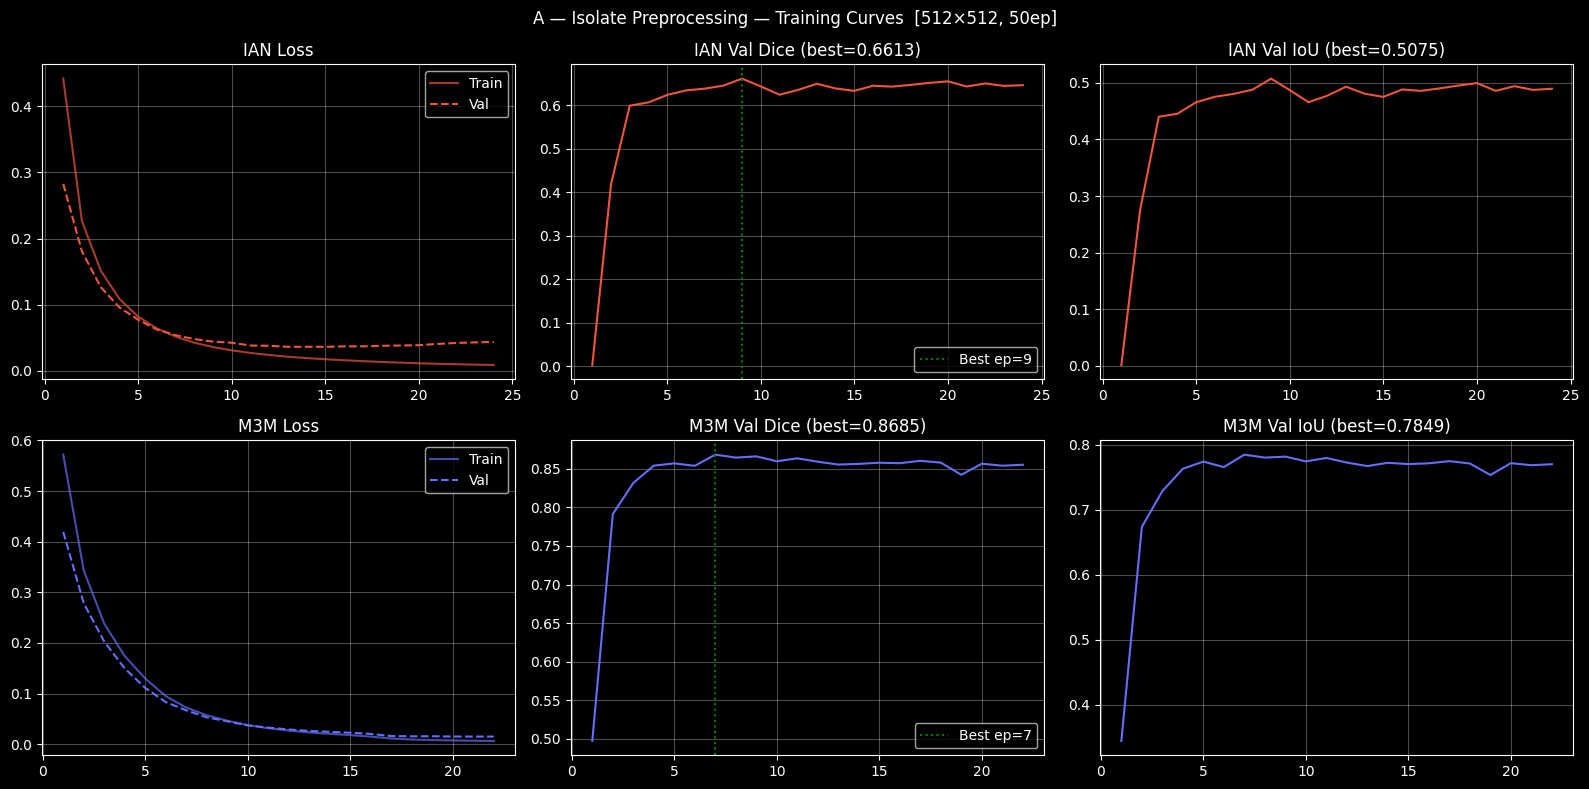

C:\Users\minud\AppData\Local\Temp\ipykernel_23212\882531382.py:67: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ian_model.load_state_dict(torch.load(ian_best, map_location=


  Results — A — Isolate Preprocessing
    IAN: Dice=0.6426  IoU=0.4872  Precision=0.6262  Recall=0.6850  mAP50=0.9762  mAP50-95=0.4211
    M3M: Dice=0.8687  IoU=0.7783  Precision=0.8810  Recall=0.8718  mAP50=1.0000  mAP50-95=1.0000

#################################################################
  B — Isolate Loss
  Active: ['Loss ON (IAN=0.6)']
#################################################################

Training: B_loss_ian | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.7096→0.6276 | Dice 0.5349 | IoU 0.3724  ✓
  Ep  5/30 | loss 0.2525→0.2581 | Dice 0.6695 | IoU 0.5178  ✓
  Ep 10/30 | loss 0.1258→0.2282 | Dice 0.6649 | IoU 0.5114
  Ep 15/30 | loss 0.0827→0.2300 | Dice 0.6596 | IoU 0.5052
  Ep 20/30 | loss 0.0597→0.2314 | Dice 0.6592 | IoU 0.5047
  Early stop @ epoch 21  (best Dice=0.6756)
  Best val Dice: 0.6756 → E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite\B_loss\B_loss_ian_best.pth

Training: B_loss_m3m | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.5061→0.4191 | Dice 0.8344 

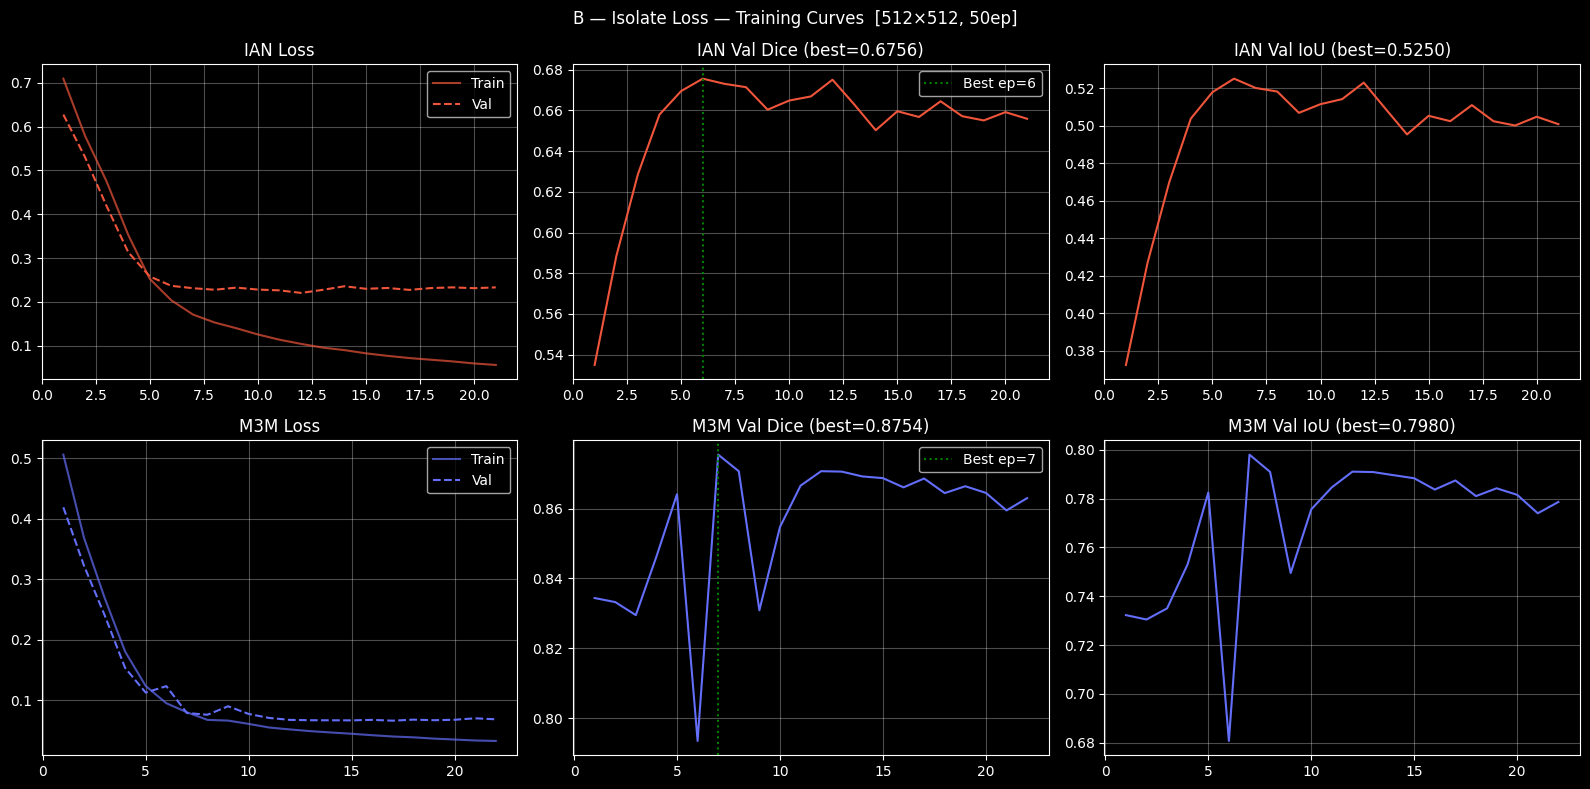

Eval B_loss/M3M: 100%|██████████| 37/37 [00:05<00:00,  6.70it/s]



  Results — B — Isolate Loss
    IAN: Dice=0.6594  IoU=0.5064  Precision=0.6312  Recall=0.7127  mAP50=0.9773  mAP50-95=0.4407
    M3M: Dice=0.8715  IoU=0.7864  Precision=0.8744  Recall=0.8825  mAP50=1.0000  mAP50-95=1.0000

#################################################################
  D — Isolate Augmentation
  Active: ['Augmentation ON']
#################################################################

Training: D_augmentation_ian | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.2265→0.1270 | Dice 0.0038 | IoU 0.0022  ✓
  Ep  5/30 | loss 0.0419→0.0383 | Dice 0.6165 | IoU 0.4565
  Ep 10/30 | loss 0.0252→0.0246 | Dice 0.6578 | IoU 0.5017  ✓
  Ep 15/30 | loss 0.0213→0.0223 | Dice 0.6544 | IoU 0.4976
  Ep 20/30 | loss 0.0178→0.0212 | Dice 0.6918 | IoU 0.5432  ✓
  Ep 25/30 | loss 0.0164→0.0216 | Dice 0.6794 | IoU 0.5285
  Ep 30/30 | loss 0.0161→0.0223 | Dice 0.6764 | IoU 0.5256
  Best val Dice: 0.6918 → E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite\D_augmentation\D_augmentation_ian_bes

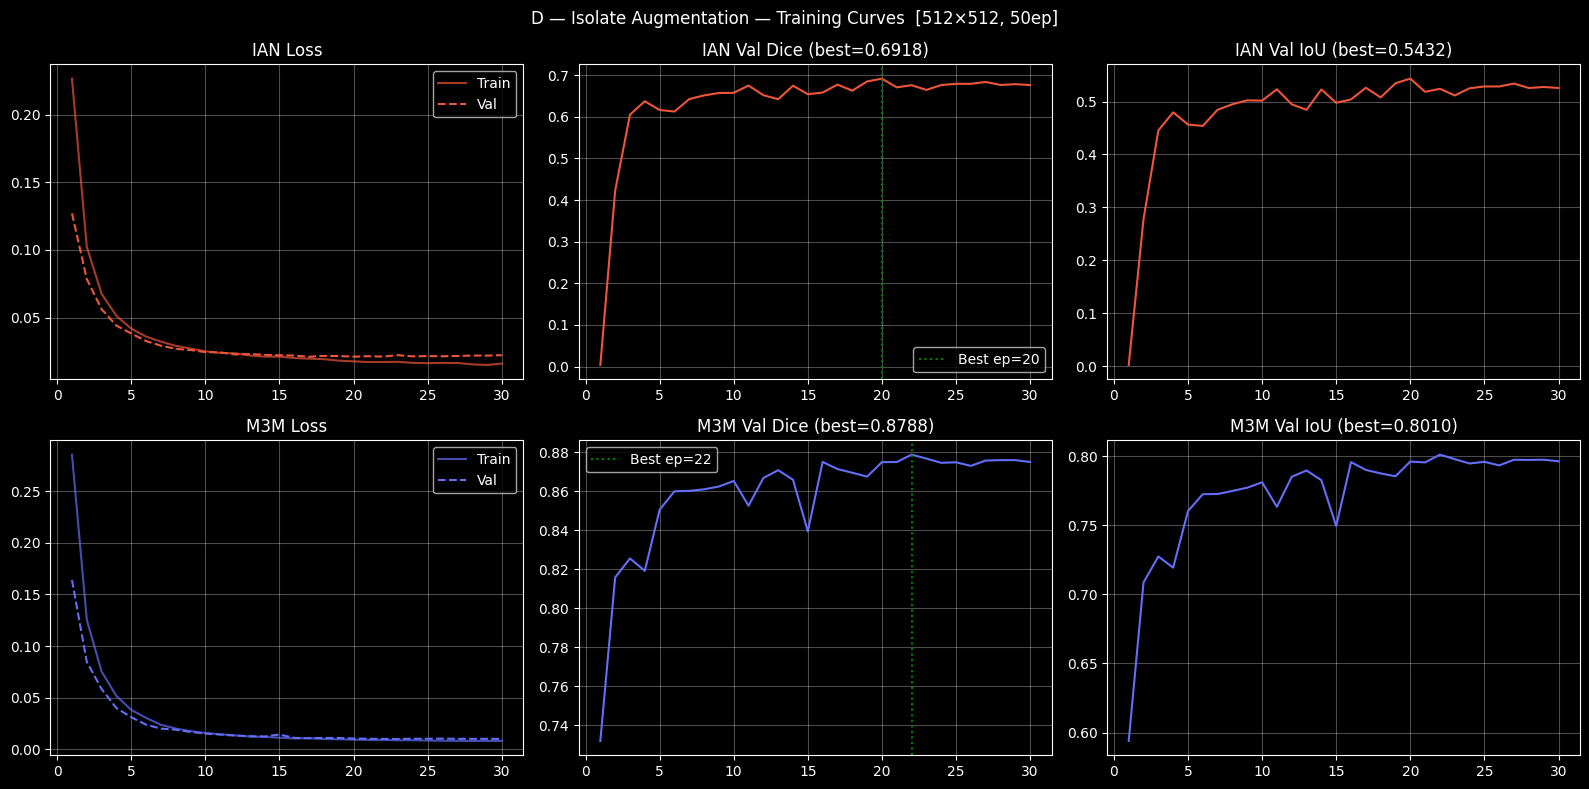

Eval D_augmentation/M3M: 100%|██████████| 37/37 [00:05<00:00,  6.77it/s]



  Results — D — Isolate Augmentation
    IAN: Dice=0.6728  IoU=0.5229  Precision=0.6789  Recall=0.6869  mAP50=0.9808  mAP50-95=0.4995
    M3M: Dice=0.8902  IoU=0.8080  Precision=0.9188  Recall=0.8726  mAP50=1.0000  mAP50-95=1.0000

✓ All runs complete (or skipped)


In [9]:
SKIP_RUNS   = []   # e.g. ['A_preprocess'] to skip a completed run
all_results = {}

for cfg in ABLATION_RUNS:
    run_id  = cfg['id']; label = cfg['label']
    run_dir = os.path.join(ABLATION_DIR, run_id)
    os.makedirs(run_dir, exist_ok=True)

    if run_id in SKIP_RUNS:
        print(f'⏭  Skipping {label}'); continue

    print(f'\n{"#"*65}')
    print(f'  {label}')
    active = []
    if cfg['preprocess'].__name__ != 'no_preprocessing': active.append('Preprocessing ON')
    if cfg['ian_dice_w'] > 0:                            active.append(f'Loss ON (IAN={cfg["ian_dice_w"]})')
    if cfg['train_tfm'] is AUGMENTATION_ON:              active.append('Augmentation ON')
    print(f'  Active: {active}')
    print(f'{"#"*65}')

    # Build datasets
    train_ds = DentalDataset(SPLITS['train'], IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              cfg['train_tfm'], cfg['preprocess'])
    val_ds   = DentalDataset(SPLITS['val'],   IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              VAL_TRANSFORM,   cfg['preprocess'])
    test_ds  = DentalDataset(SPLITS['test'],  IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              VAL_TRANSFORM,   cfg['preprocess'])

    train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
    val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)
    test_loader  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

    ian_criterion = DiceBCELoss(dice_weight=cfg['ian_dice_w'])
    m3m_criterion = DiceBCELoss(dice_weight=cfg['m3m_dice_w'])

    # Train IAN
    ian_model = build_unet().to(DEVICE)
    ian_history, ian_best = train_one_model(ian_model, ian_criterion, train_loader, val_loader,
                                             f'{run_id}_ian', run_dir, mask_idx=0)
    # Train M3M
    m3m_model = build_unet().to(DEVICE)
    m3m_history, m3m_best = train_one_model(m3m_model, m3m_criterion, train_loader, val_loader,
                                             f'{run_id}_m3m', run_dir, mask_idx=1)

    # Training curves
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    fig.suptitle(f'{label} — Training Curves  [512×512, 50ep]', fontsize=12)
    for hist, lbl, col, row in [(ian_history,'IAN','#EF553B',axes[0]),
                                 (m3m_history,'M3M','#636EFA',axes[1])]:
        eps = range(1, len(hist['val_dice'])+1)
        row[0].plot(eps, hist['train_loss'], color=col, alpha=0.7, label='Train')
        row[0].plot(eps, hist['val_loss'],   color=col, ls='--', label='Val')
        row[0].set_title(f'{lbl} Loss'); row[0].legend(); row[0].grid(alpha=0.3)
        best_ep = np.argmax(hist['val_dice'])+1
        row[1].plot(eps, hist['val_dice'], color=col)
        row[1].axvline(best_ep, color='green', ls=':', label=f'Best ep={best_ep}')
        row[1].set_title(f'{lbl} Val Dice (best={max(hist["val_dice"]):.4f})')
        row[1].legend(); row[1].grid(alpha=0.3)
        row[2].plot(eps, hist['val_iou'], color=col)
        row[2].set_title(f'{lbl} Val IoU (best={max(hist["val_iou"]):.4f})')
        row[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, 'training_curves.png'), dpi=120, bbox_inches='tight')
    plt.show()

    # Evaluate
    ian_model.load_state_dict(torch.load(ian_best, map_location='cpu')); ian_model.to(DEVICE)
    m3m_model.load_state_dict(torch.load(m3m_best, map_location='cpu')); m3m_model.to(DEVICE)
    ian_metrics = full_evaluation(ian_model, test_loader, 0, f'{run_id}/IAN')
    m3m_metrics = full_evaluation(m3m_model, test_loader, 1, f'{run_id}/M3M')
    all_results[run_id] = {'label': label, 'IAN': ian_metrics, 'M3M': m3m_metrics}

    print(f'\n  Results — {label}')
    for cls, m in [('IAN', ian_metrics), ('M3M', m3m_metrics)]:
        print(f'    {cls}: ' + '  '.join(f'{k}={v:.4f}' for k,v in m.items()))

    with open(os.path.join(run_dir, 'test_metrics.json'), 'w') as f:
        json.dump({
            'run': run_id, 'label': label, 'img_size': IMG_SIZE, 'epochs': EPOCHS,
            'config': {'preprocess': cfg['preprocess'].__name__,
                       'ian_dice_weight': cfg['ian_dice_w'], 'm3m_dice_weight': cfg['m3m_dice_w'],
                       'augmentation': 'ON' if cfg['train_tfm'] is AUGMENTATION_ON else 'OFF'},
            'IAN': {k: round(v,4) for k,v in ian_metrics.items()},
            'M3M': {k: round(v,4) for k,v in m3m_metrics.items()},
        }, f, indent=2)

print('\n✓ All runs complete (or skipped)')


## 10. Load Metrics for Skipped Runs

In [10]:
for cfg in ABLATION_RUNS:
    run_id = cfg['id']
    if run_id not in SKIP_RUNS: continue
    path = os.path.join(ABLATION_DIR, run_id, 'test_metrics.json')
    if not os.path.exists(path):
        print(f'⚠️  No saved metrics at {path}'); continue
    with open(path) as f: saved = json.load(f)
    all_results[run_id] = {'label': saved.get('label', cfg['label']),
                            'IAN': saved['IAN'], 'M3M': saved['M3M']}
    print(f'✓ Loaded {run_id}: IAN mAP50-95={saved["IAN"]["mAP50-95"]:.4f}')

print(f'Results loaded: {list(all_results.keys())}')


Results loaded: ['A_preprocess', 'B_loss', 'D_augmentation']


## 11. Results Table & Charts


ISOLATE-ONE-ONLY ABLATION — 512×512 — TEST SET RESULTS
(Encoder fixed: ResNet-50 + ImageNet  |  Epochs: 50  |  Early stop patience: 15)
                      Run  IAN Dice  IAN IoU  IAN mAP50  IAN mAP50-95  M3M Dice  M3M mAP50-95
A — Isolate Preprocessing    0.6426   0.4872     0.9762        0.4211    0.8687           1.0
         B — Isolate Loss    0.6594   0.5064     0.9773        0.4407    0.8715           1.0
 D — Isolate Augmentation    0.6728   0.5229     0.9808        0.4995    0.8902           1.0

✓ Saved CSV: E:\IIT\NEW_FYP\MODELS\Ablation_Isolate_v3_lite


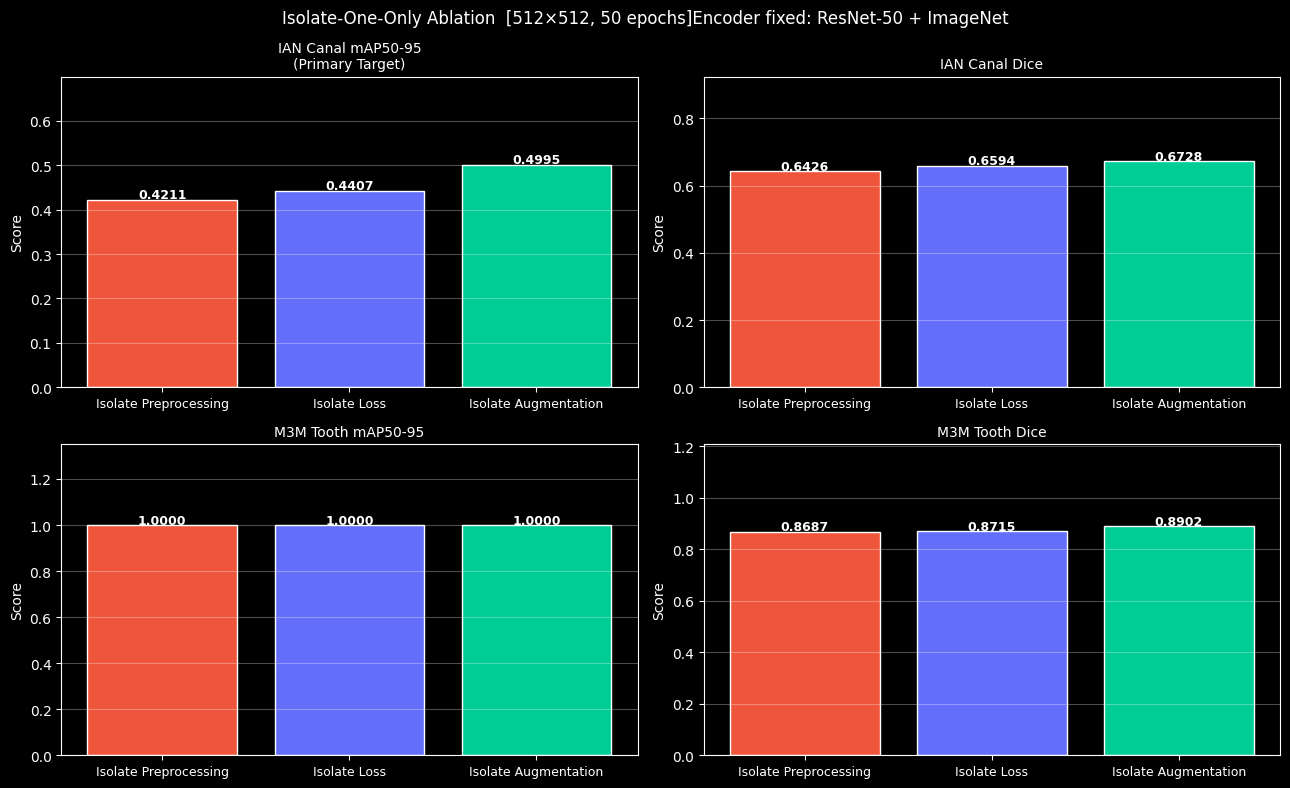

✓ Chart saved


In [11]:
rows = []
for run_id in ['A_preprocess', 'B_loss', 'D_augmentation']:
    if run_id not in all_results:
        print(f'⚠️  {run_id} missing — skipping'); continue
    res = all_results[run_id]
    rows.append({
        'Run':          res['label'],
        'IAN Dice':     round(res['IAN']['Dice'],     4),
        'IAN IoU':      round(res['IAN']['IoU'],      4),
        'IAN mAP50':    round(res['IAN']['mAP50'],    4),
        'IAN mAP50-95': round(res['IAN']['mAP50-95'], 4),
        'M3M Dice':     round(res['M3M']['Dice'],     4),
        'M3M mAP50-95': round(res['M3M']['mAP50-95'], 4),
    })

df = pd.DataFrame(rows)
print('\n' + '='*95)
print('ISOLATE-ONE-ONLY ABLATION — 512×512 — TEST SET RESULTS')
print('(Encoder fixed: ResNet-50 + ImageNet  |  Epochs: 50  |  Early stop patience: 15)')
print('='*95)
print(df.to_string(index=False))
print('='*95)
df.to_csv(os.path.join(ABLATION_DIR, 'ablation_results.csv'), index=False)
print(f'\n✓ Saved CSV: {ABLATION_DIR}')

# ── Bar charts ────────────────────────────────────────────────────────────────
if rows:
    metrics_to_plot = [
        ('IAN mAP50-95', 'IAN Canal mAP50-95\n(Primary Target)'),
        ('IAN Dice',     'IAN Canal Dice'),
        ('M3M mAP50-95', 'M3M Tooth mAP50-95'),
        ('M3M Dice',     'M3M Tooth Dice'),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    fig.suptitle('Isolate-One-Only Ablation  [512×512, 50 epochs]'
                  'Encoder fixed: ResNet-50 + ImageNet', fontsize=12)
    colors     = ['#EF553B', '#636EFA', '#00CC96']
    run_labels = [r['Run'].split('—')[1].strip() for r in rows]
    for ax, (col, title) in zip(axes.flat, metrics_to_plot):
        vals = [r[col] for r in rows]
        bars = ax.bar(run_labels, vals, color=colors[:len(vals)], edgecolor='white')
        ax.set_title(title, fontsize=10)
        ax.set_ylim(0, max(vals)*1.3+0.05)
        ax.set_ylabel('Score'); ax.tick_params(axis='x', labelsize=9); ax.grid(axis='y', alpha=0.3)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                    f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(ABLATION_DIR, 'ablation_comparison.png'), dpi=140, bbox_inches='tight')
    plt.show()
    print('✓ Chart saved')


## 12. Notes on Using These Results

**These are proxy results, not final dissertation numbers.**  
At 512×512, the IAN canal (originally 1–3px wide at 1024) becomes borderline sub-pixel,  
so absolute Dice/mAP values will be lower than the full-resolution runs. Do not compare  
these numbers directly to your YOLO or full U-Net results.

**What you can use them for:**
- Identifying which component contributes the most in isolation (relative ranking)
- Deciding which components to prioritise in the full 1024×512 final runs
- Catching implementation bugs before investing in long training runs

**Interpreting the runs:**
- **Run A best** → Surgical CLAHE contrast enhancement carries signal even without Dice loss or augmentation
- **Run B best** → Loss function is the dominant factor (expected for IAN due to extreme class imbalance)
- **Run D best** → The model is data-hungry and geometric/photometric augmentation helps most
